# Segmentación de inmuebles en arriendo con algoritmos no supervisados — Parte 2
### PCA: reducir la dimensionalidad y visualizar los segmentos

---

**Universidad de Cundinamarca** — Esp. Inteligencia Artificial

**CADI:** Introducción a Machine Learning · Período 2026-2

**Estudiante:** Ruby Dayana Cárdenas Gómez

**Docente:** Ing. Wilson Rojas Reales, PhD(c)

**Repositorio GitHub:** `https://github.com/RubyDayana/ml-no-supervisado-inmuebles.git`

---

### ¿Qué se hace en este notebook?

En el notebook 1 agrupé los inmuebles con K-Means usando cuatro variables. Aquí aplico **PCA (Análisis de
Componentes Principales)** al dataset inmobiliario, como pide la actividad complementaria: reducir la
dimensionalidad, estudiar la **varianza explicada** y **visualizar los grupos** de K-Means en un plano de dos
dimensiones. Se sigue el script `Algoritmo_InmueblesPCA.py` del docente, modificado para leer el Excel.

Lo que se hace, en orden:

1. Preprocesar el dataset (escalar las variables numéricas y codificar la localidad) y contar las **dimensiones**.
2. **Experimento A:** K-Means sobre los datos preprocesados completos.
3. **PCA:** varianza explicada por componente, gráfica de sedimentación, cargas de cada variable y plano PC1–PC2.
4. Analizar **qué información se pierde** al quedarse con dos componentes.
5. **Experimento B:** K-Means sobre los componentes principales, en lugar de sobre las variables, y compararlo con el A.
6. Una **variante informativa**: ¿qué pasa con PCA si solo se usan las variables que realmente describen al inmueble?
7. **Responder las 7 preguntas** del enunciado y recomendar un enfoque.

### Glosario rápido

| Término | Qué significa aquí |
|---|---|
| **Reducción de dimensionalidad** | Representar los datos con menos variables conservando la mayor parte de la información. |
| **Componente principal (PC)** | Una nueva variable que es una combinación de las originales. El PC1 es la dirección en la que los datos varían más; el PC2, la mayor variación restante en una dirección perpendicular al PC1; y así sucesivamente. |
| **Varianza explicada** | Qué fracción de la variabilidad total de los datos captura un componente. |
| **Cargas (loadings)** | Los pesos con que cada variable original entra en un componente: muestran qué significa ese componente. |
| **ARI (índice de Rand ajustado)** | Mide qué tanto coinciden dos agrupaciones: 1 es idénticas, 0 es el nivel que se esperaría por azar. |

---
## 1. Datos y preprocesamiento

Se carga el mismo Excel del notebook 1 y se aplican las mismas decisiones: las columnas se renombran, se descarta
`Estrato_2` (la columna duplicada sin información) y el identificador `Inmueble` se **conserva pero no se usa**
como característica.

El script del docente usa cinco variables numéricas (precio, área, habitaciones, baños y antigüedad) y una
categórica (localidad). Las numéricas se **estandarizan** (media 0, desviación 1), porque PCA, igual que K-Means,
depende de las escalas; y la localidad se convierte con **one-hot encoding** en tres columnas de 0 y 1
(una por localidad), porque un algoritmo de distancias no puede operar con texto.

In [1]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
SEMILLA = 42

URL_DATOS = ("https://raw.githubusercontent.com/RubyDayana/ml-no-supervisado-inmuebles/"
             "main/datos/DATASET_Inmuebles.xlsx")
RUTA = "datos/DATASET_Inmuebles.xlsx"

# Nombres limpios para las 10 columnas del Excel (el encabezado original trae un error de digitación
# en "Antigüedad" y la columna "Estrato" aparece dos veces).
NOMBRES = ["Inmueble", "Area_m2", "Habitaciones", "Estrato", "Precio_arriendo", "Banos",
           "Antiguedad_anios", "Localidad", "Tipo_inmueble", "Estrato_2"]


def cargar_crudo():
    """Lee el Excel del docente. Si no está en la carpeta datos/ (por ejemplo en Colab), lo descarga del repositorio."""
    if not os.path.exists(RUTA):
        os.makedirs("datos", exist_ok=True)
        urllib.request.urlretrieve(URL_DATOS, RUTA)
    return pd.read_excel(RUTA)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

df = cargar_crudo()
df.columns = NOMBRES
df = df.drop(columns="Estrato_2")      # columna duplicada sin información (ver notebook 1)

ids = df["Inmueble"]                   # se conserva para interpretar, NO se usa como característica

variables_numericas = ["Precio_arriendo", "Area_m2", "Habitaciones", "Banos", "Antiguedad_anios"]
variables_categoricas = ["Localidad"]

X = df[variables_numericas + variables_categoricas]
print("Columnas del Excel (sin la duplicada):", df.shape[1], "->", list(df.columns))
print("Características usadas:", X.shape[1], "->", list(X.columns))

Columnas del Excel (sin la duplicada): 9 -> ['Inmueble', 'Area_m2', 'Habitaciones', 'Estrato', 'Precio_arriendo', 'Banos', 'Antiguedad_anios', 'Localidad', 'Tipo_inmueble']
Características usadas: 6 -> ['Precio_arriendo', 'Area_m2', 'Habitaciones', 'Banos', 'Antiguedad_anios', 'Localidad']


**Cuenta de dimensiones.** El Excel trae 10 columnas, pero de ellas el identificador no es una característica y
`Estrato_2` se descartó. Con las variables que usa el script del docente, el conjunto tiene **6 características de
entrada** (5 numéricas y 1 categórica). Al preprocesar, la localidad se convierte en 3 columnas y el conjunto pasa a **8
dimensiones**; y después de PCA quedarán **2**. Esa es la respuesta a la pregunta 1 del enunciado.

In [2]:
preprocesamiento = ColumnTransformer(transformers=[
    ("numericas", StandardScaler(), variables_numericas),
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), variables_categoricas),
])
X_preparado = preprocesamiento.fit_transform(X)

nombres_cols = (list(variables_numericas)
                + list(preprocesamiento.named_transformers_["categoricas"].get_feature_names_out()))

print("Dimensiones después del preprocesamiento:", X_preparado.shape)
print("Columnas resultantes:", nombres_cols)
print()
print("Comprobación: media y desviación de cada columna escalada")
print(pd.DataFrame(X_preparado, columns=nombres_cols).agg(["mean", "std"]).round(3).T.to_string())

Dimensiones después del preprocesamiento: (1000, 8)
Columnas resultantes: ['Precio_arriendo', 'Area_m2', 'Habitaciones', 'Banos', 'Antiguedad_anios', 'Localidad_Chapinero', 'Localidad_Suba', 'Localidad_Usaquén']

Comprobación: media y desviación de cada columna escalada
                      mean    std
Precio_arriendo     -0.000  1.001
Area_m2             -0.000  1.001
Habitaciones        -0.000  1.001
Banos                0.000  1.001
Antiguedad_anios     0.000  1.001
Localidad_Chapinero  0.333  0.472
Localidad_Suba       0.334  0.472
Localidad_Usaquén    0.333  0.472


Las cinco variables numéricas quedan con media 0 y desviación 1 (el 1.001 es la corrección de muestra de
pandas). Las tres columnas de localidad son 0 y 1, no se estandarizan (como en el script) y tienen una desviación de
0.47. Por eso la varianza total del conjunto no es 8 sino **5 + 3 × 0.222 ≈ 5.67**, un detalle que se
verá en la tabla de autovalores.

In [3]:
# Función para renumerar los clusters de menor a mayor precio (K-Means los numera al azar)
def ordenar_por_precio(etiquetas):
    orden = df["Precio_arriendo"].groupby(etiquetas).mean().sort_values().index
    mapa = {viejo: nuevo for nuevo, viejo in enumerate(orden)}
    return np.array([mapa[e] for e in etiquetas])

COLORES = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]

def eta_cuadrado(variable, etiquetas):
    """Proporción de la varianza de una variable que explica la pertenencia al cluster (0 a 1)."""
    v = df[variable]
    total = ((v - v.mean()) ** 2).sum()
    entre = sum(len(g) * (g.mean() - v.mean()) ** 2 for _, g in v.groupby(etiquetas))
    return entre / total

---
## 2. Experimento A: K-Means sobre los datos preprocesados

Es el paso 3 del script del docente: K-Means con tres grupos sobre **todas** las columnas preprocesadas (las 5
numéricas escaladas y las 3 de localidad).

In [4]:
kmeans_A = KMeans(n_clusters=3, random_state=42, n_init=10)
grupos_A = ordenar_por_precio(kmeans_A.fit_predict(X_preparado))
df["Grupo_KMeans"] = grupos_A

print("Inmuebles por grupo:", np.bincount(grupos_A).tolist())
print(f"Silueta (en el espacio preprocesado de 8 dimensiones): {silhouette_score(X_preparado, grupos_A):.3f}")
print()
print("Perfil comercial de los grupos (promedios):")
print(df.groupby("Grupo_KMeans")[variables_numericas].mean().round(2).to_string())
print()
print("Distribución por localidad dentro de cada grupo:")
print(pd.crosstab(df["Grupo_KMeans"], df["Localidad"], normalize="index").round(2).to_string())

Inmuebles por grupo: [293, 335, 372]
Silueta (en el espacio preprocesado de 8 dimensiones): 0.278

Perfil comercial de los grupos (promedios):
              Precio_arriendo  Area_m2  Habitaciones  Banos  Antiguedad_anios
Grupo_KMeans                                                                 
0                  1974711.38    60.85          1.84    2.0              8.49
1                  2063615.30    62.21          1.87    1.0              8.60
2                  6353185.81   156.07          4.03    1.5              8.31

Distribución por localidad dentro de cada grupo:
Localidad     Chapinero  Suba  Usaquén
Grupo_KMeans                          
0                  0.36  0.35     0.29
1                  0.34  0.35     0.32
2                  0.31  0.31     0.38


**Resultado inesperado.** Los grupos 0 y 1 son, comercialmente, **casi el mismo grupo**:

| Grupo | Inmuebles | Arriendo | Área | Habitaciones | Baños | Antigüedad |
|---|---|---|---|---|---|---|
| 0 | 293 | 1 974 711 | 60.9 m² | 1.84 | **2.0** | 8.5 |
| 1 | 335 | 2 063 615 | 62.2 m² | 1.87 | **1.0** | 8.6 |
| 2 | 372 | 6 353 186 | 156.1 m² | 4.03 | 1.5 | 8.3 |

Los grupos 0 y 1 tienen el mismo precio (diferencia de 4.5 %), el mismo área y las mismas habitaciones; lo único que los
distingue es el **número de baños** (2 frente a 1). El tercer grupo es el premium. Es decir, con las 8 columnas
K-Means no encontró "económico, intermedio y premium" como en el notebook 1, sino "pequeño con dos baños", "pequeño
con un baño" y "grande". La silueta, 0.278, indica una estructura débil. La causa se aclara con PCA.

---
## 3. PCA: ¿cuánta información conserva cada componente?

Primero se calculan **todos** los componentes (8, tantos como columnas) para ver cómo se reparte la varianza. Como
las variables están estandarizadas, cada una aporta una varianza de 1 y la varianza total es 8; el **autovalor** de un
componente indica cuántas "variables originales" de varianza concentra.

In [5]:
pca_completo = PCA().fit(X_preparado)

tabla_var = pd.DataFrame({
    "Componente": [f"PC{i + 1}" for i in range(8)],
    "Autovalor": pca_completo.explained_variance_,
    "Varianza explicada (%)": pca_completo.explained_variance_ratio_ * 100,
    "Acumulada (%)": pca_completo.explained_variance_ratio_.cumsum() * 100,
}).round(3)
print(tabla_var.to_string(index=False))

acum = pca_completo.explained_variance_ratio_.cumsum()
print()
print("Componentes necesarios para conservar al menos el 80 % de la varianza:", int(np.argmax(acum >= 0.80)) + 1)
print("Componentes necesarios para conservar al menos el 90 % de la varianza:", int(np.argmax(acum >= 0.90)) + 1)
print("Componentes con autovalor > 1 (criterio de Kaiser)                    :", int((pca_completo.explained_variance_ > 1).sum()))

Componente  Autovalor  Varianza explicada (%)  Acumulada (%)
       PC1      2.559                  45.106         45.106
       PC2      1.007                  17.756         62.862
       PC3      0.994                  17.522         80.384
       PC4      0.336                   5.925         86.309
       PC5      0.333                   5.864         92.173
       PC6      0.245                   4.316         96.489
       PC7      0.199                   3.511        100.000
       PC8      0.000                   0.000        100.000

Componentes necesarios para conservar al menos el 80 % de la varianza: 3
Componentes necesarios para conservar al menos el 90 % de la varianza: 5
Componentes con autovalor > 1 (criterio de Kaiser)                    : 2


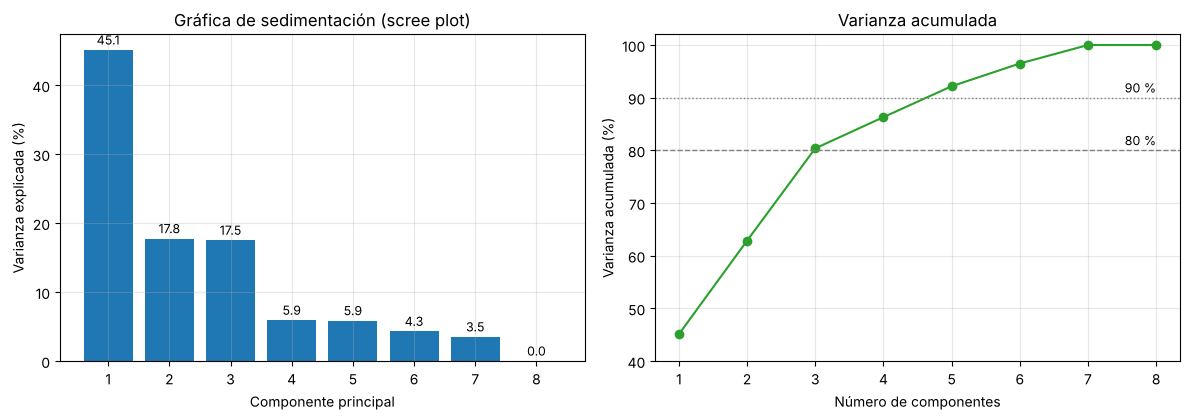

In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.3))
x = np.arange(1, 9)
ejes[0].bar(x, pca_completo.explained_variance_ratio_ * 100, color="tab:blue")
for i, v in enumerate(pca_completo.explained_variance_ratio_ * 100):
    ejes[0].text(i + 1, v + 0.8, f"{v:.1f}", ha="center", fontsize=9)
ejes[0].set(xlabel="Componente principal", ylabel="Varianza explicada (%)", title="Gráfica de sedimentación (scree plot)")
ejes[0].set_xticks(x)

ejes[1].plot(x, acum * 100, marker="o", color="tab:green")
ejes[1].axhline(80, ls="--", color="gray", lw=1); ejes[1].axhline(90, ls=":", color="gray", lw=1)
ejes[1].text(8, 81, "80 %", ha="right", fontsize=9); ejes[1].text(8, 91, "90 %", ha="right", fontsize=9)
ejes[1].set(xlabel="Número de componentes", ylabel="Varianza acumulada (%)", title="Varianza acumulada")
ejes[1].set_xticks(x); ejes[1].set_ylim(40, 102)
plt.tight_layout(); plt.show()

**Lectura de la tabla y de la gráfica de sedimentación.**

- El **PC1 concentra el 45.1 %** de la varianza. Es, con diferencia, el componente más importante.
- PC2 y PC3 son casi idénticos (17.8 % y 17.5 %; autovalores 1.007 y 0.994), y luego la varianza cae a cerca del
  6 % por componente. El "codo" de la gráfica está después del tercer componente.
- Para conservar el **80 %** de la varianza hacen falta **3 componentes**; para el **90 %**, **5**. Con solo 2
  componentes se conserva el **62.9 %**.
- El octavo componente tiene varianza **cero**: las tres columnas de localidad suman siempre 1, así que una de
  ellas es redundante (colinealidad perfecta) y el espacio de datos tiene en realidad 7 dimensiones.
- El criterio de Kaiser (conservar componentes con autovalor mayor que 1) indica 2, pero PC2 (1.007) y PC3 (0.994)
  quedan a ambos lados del umbral por una milésima, así que la regla no es concluyente aquí.

### 3.1. Reducir a dos componentes

Ahora se hace lo que pide el script: reducir a **dos** componentes. La transformación conserva los 1 000
inmuebles, pero cada uno queda representado por dos coordenadas (PC1, PC2) en lugar de ocho columnas.

In [7]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_preparado)

print("Dimensiones originales después del preprocesamiento:", X_preparado.shape)
print("Dimensiones después de PCA                         :", X_pca.shape)
print()
print("Varianza explicada por componente:", pca.explained_variance_ratio_.round(4))
print(f"Varianza acumulada (PC1 + PC2)    : {pca.explained_variance_ratio_.sum():.4f}  ->  {pca.explained_variance_ratio_.sum() * 100:.1f} %")
print(f"Información que se pierde         : {(1 - pca.explained_variance_ratio_.sum()) * 100:.1f} %")

Dimensiones originales después del preprocesamiento: (1000, 8)
Dimensiones después de PCA                         : (1000, 2)

Varianza explicada por componente: [0.4511 0.1776]
Varianza acumulada (PC1 + PC2)    : 0.6286  ->  62.9 %
Información que se pierde         : 37.1 %


### 3.2. ¿Qué significa cada componente? Las cargas

Un componente es una mezcla de las variables originales. Los pesos de esa mezcla (las **cargas**) dicen qué
representa. Se muestran para los tres primeros componentes.

                       PC1    PC2    PC3
Precio_arriendo      0.582 -0.003 -0.021
Area_m2              0.574 -0.046  0.014
Habitaciones         0.573 -0.024  0.027
Banos                0.022  0.707  0.707
Antiguedad_anios    -0.037 -0.705  0.706
Localidad_Chapinero -0.011 -0.003 -0.004
Localidad_Suba      -0.017 -0.010  0.011
Localidad_Usaquén    0.028  0.013 -0.007


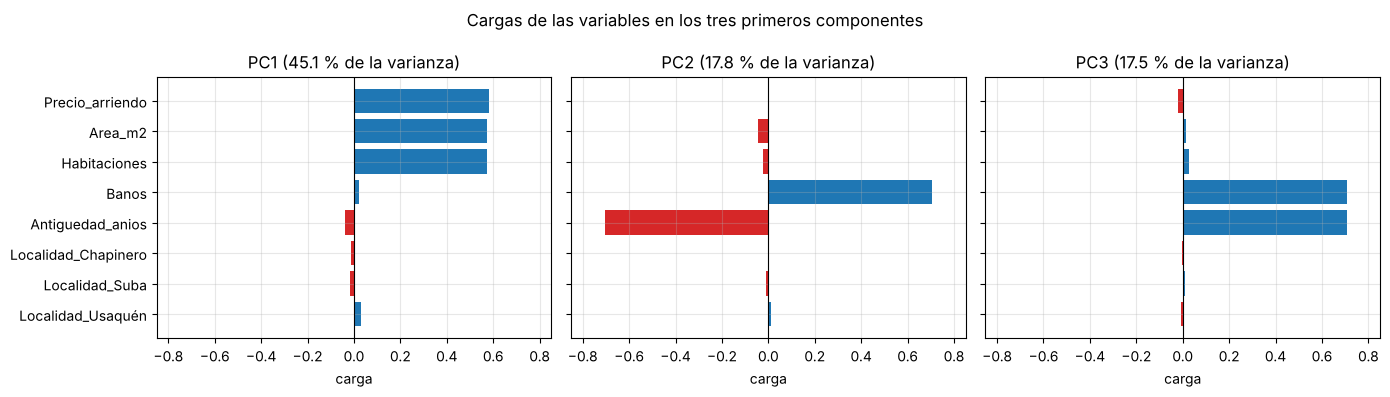

In [8]:
cargas = pd.DataFrame(pca_completo.components_[:3].T, index=nombres_cols, columns=["PC1", "PC2", "PC3"])
print(cargas.round(3).to_string())

fig, ejes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for eje, pc in zip(ejes, cargas.columns):
    colores = ["tab:blue" if v >= 0 else "tab:red" for v in cargas[pc]]
    eje.barh(cargas.index, cargas[pc], color=colores)
    eje.axvline(0, color="black", lw=0.8)
    eje.set(title=f"{pc} ({pca_completo.explained_variance_ratio_[int(pc[2]) - 1] * 100:.1f} % de la varianza)",
            xlabel="carga", xlim=(-0.85, 0.85))
    eje.invert_yaxis()
plt.suptitle("Cargas de las variables en los tres primeros componentes")
plt.tight_layout(); plt.show()

**Qué significa cada componente.**

- **PC1 = tamaño y valor del inmueble.** Precio (0.582), área (0.574) y habitaciones (0.573) cargan casi igual
  y con el mismo signo: PC1 es un "índice de tamaño y precio". Un inmueble con PC1 alto es grande, tiene muchas
  habitaciones y es caro.
- **PC2 = contraste entre baños y antigüedad.** Baños (+0.707) y antigüedad (−0.705) con signos opuestos.
- **PC3 = suma de baños y antigüedad.** Baños (+0.707) y antigüedad (+0.706).
- **La localidad no carga en ninguno** (valores cercanos a 0): no contribuye a las direcciones de mayor variación.

Como PC2 y PC3 tienen autovalores casi iguales, sus ejes **no están definidos de forma única**: cualquier rotación
del par (PC2, PC3) explica exactamente lo mismo. Lo que sí tiene sentido es el plano que forman juntos: el de las
dos variables, baños y antigüedad, que no se relacionan con el precio ni con el tamaño.

---
## 4. Visualizar los grupos en el plano PC1–PC2

Esta es la gráfica central de la actividad: los 1 000 inmuebles en el plano de los dos primeros componentes,
coloreados según el grupo de K-Means del experimento A. A su lado, los mismos puntos coloreados por **precio**
(para interpretar el PC1) y por **localidad**.

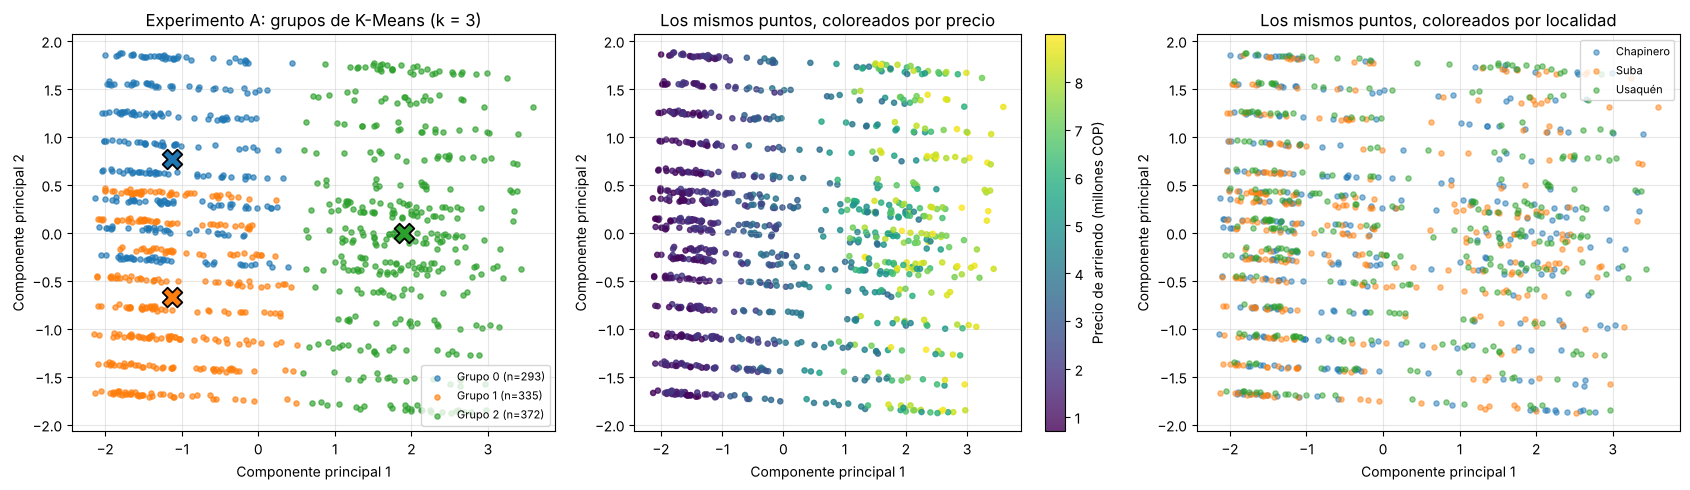

In [9]:
centros_pca = pca.transform(kmeans_A.cluster_centers_)
orden_interno = df["Precio_arriendo"].groupby(kmeans_A.labels_).mean().sort_values().index   # ordena los centroides
centros_pca = centros_pca[list(orden_interno)]

fig, ejes = plt.subplots(1, 3, figsize=(17, 5))

for g in range(3):
    m = grupos_A == g
    ejes[0].scatter(X_pca[m, 0], X_pca[m, 1], s=14, alpha=0.65, color=COLORES[g], label=f"Grupo {g} (n={m.sum()})")
    ejes[0].scatter(*centros_pca[g], marker="X", s=200, color=COLORES[g], edgecolor="black", linewidth=1.3, zorder=5)
ejes[0].set(xlabel="Componente principal 1", ylabel="Componente principal 2",
            title="Experimento A: grupos de K-Means (k = 3)")
ejes[0].legend(fontsize=8)

sc = ejes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=df["Precio_arriendo"] / 1e6, cmap="viridis", s=14, alpha=0.8)
plt.colorbar(sc, ax=ejes[1], label="Precio de arriendo (millones COP)")
ejes[1].set(xlabel="Componente principal 1", ylabel="Componente principal 2", title="Los mismos puntos, coloreados por precio")

for i, loc in enumerate(sorted(df["Localidad"].unique())):
    m = (df["Localidad"] == loc).values
    ejes[2].scatter(X_pca[m, 0], X_pca[m, 1], s=14, alpha=0.5, color=COLORES[i], label=loc)
ejes[2].set(xlabel="Componente principal 1", ylabel="Componente principal 2", title="Los mismos puntos, coloreados por localidad")
ejes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Qué muestra el plano PC1–PC2.**

- **A lo largo de PC1** el precio crece de forma continua (panel central): los inmuebles pequeños y baratos quedan
  a la izquierda y los grandes y caros a la derecha. El grupo premium (verde) ocupa claramente la derecha.
- **A lo largo de PC2** no ocurre nada comercial: el eje vertical se ve como **franjas horizontales**, porque
  baños (2 valores) y antigüedad (8 valores) son variables discretas y generan una cuadrícula. Los grupos 0 y 1 se
  separan por una frontera horizontal cerca de PC2 ≈ 0.4: es decir, se separan por baños, no por valor.
- **Por localidad** (panel derecho) los puntos se mezclan por completo: la ubicación no organiza el plano.
- No hay vacíos que separen los grupos; los bordes son zonas de transición continua.

### 4.1. Biplot: variables y inmuebles en el mismo plano

Un *biplot* dibuja sobre el plano de los inmuebles flechas que representan las variables originales. Una flecha
apunta hacia donde esa variable aumenta; flechas que apuntan igual indican variables correlacionadas.

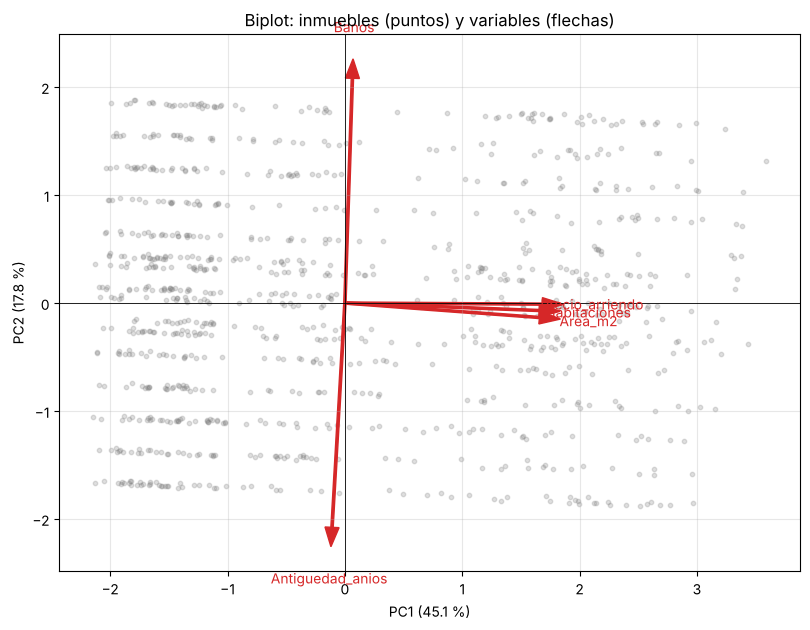

In [10]:
fig, eje = plt.subplots(figsize=(8.2, 6.4))
eje.scatter(X_pca[:, 0], X_pca[:, 1], s=10, alpha=0.25, color="gray")
escala = 3.2
for nombre, (c1, c2) in zip(nombres_cols, pca.components_.T):
    if nombre.startswith("Localidad"):
        continue
    eje.arrow(0, 0, c1 * escala, c2 * escala, color="tab:red", width=0.02, head_width=0.12, length_includes_head=True)
    eje.text(c1 * escala * 1.13, c2 * escala * 1.13, nombre, color="tab:red", ha="center", va="center", fontsize=10)
eje.set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f} %)", ylabel=f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f} %)",
        title="Biplot: inmuebles (puntos) y variables (flechas)")
eje.axhline(0, color="black", lw=0.6); eje.axvline(0, color="black", lw=0.6)
plt.tight_layout(); plt.show()

En el biplot, precio, área y habitaciones son tres flechas casi idénticas que apuntan a la derecha: están
correlacionadas y PCA las resume en un solo eje (PC1). Baños y antigüedad apuntan hacia arriba y hacia abajo; eso no
significa que estén relacionadas entre sí (su correlación es −0.01), sino que el algoritmo las reparte entre PC2 y
PC3. Las flechas de baños y antigüedad son perpendiculares a las de precio y área: no se relacionan con ellas.

---
## 5. ¿Qué información se pierde con dos componentes?

PCA se puede deshacer: con `inverse_transform` se reconstruyen las 8 columnas a partir de las 2 coordenadas. La
diferencia entre lo reconstruido y lo original es exactamente la información perdida. Para cada variable se mide
qué fracción de su varianza se recupera (R²).

           Variable  Varianza recuperada con 2 PC (%)
    Precio_arriendo                              86.6
            Area_m2                              84.4
       Habitaciones                              84.0
              Banos                              50.4
   Antiguedad_anios                              50.4
Localidad_Chapinero                               0.1
     Localidad_Suba                               0.4
  Localidad_Usaquén                               1.0

Error de reconstrucción promedio por celda (en desviaciones estándar): 0.513


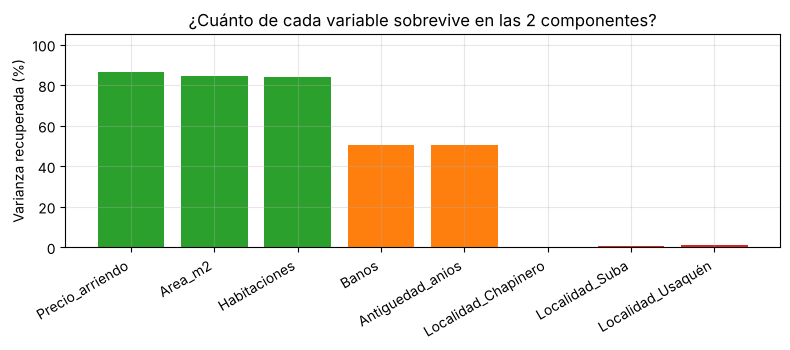

In [11]:
X_rec = pca.inverse_transform(X_pca)
r2 = 1 - ((X_preparado - X_rec) ** 2).sum(axis=0) / ((X_preparado - X_preparado.mean(axis=0)) ** 2).sum(axis=0)

recuperada = pd.DataFrame({"Variable": nombres_cols, "Varianza recuperada con 2 PC (%)": (r2 * 100).round(1)})
print(recuperada.to_string(index=False))
print()
print(f"Error de reconstrucción promedio por celda (en desviaciones estándar): {np.sqrt(((X_preparado - X_rec) ** 2).mean()):.3f}")

fig, eje = plt.subplots(figsize=(8, 3.6))
eje.bar(nombres_cols, r2 * 100, color=["tab:green" if v > 0.8 else "tab:orange" if v > 0.3 else "tab:red" for v in r2])
eje.set(ylabel="Varianza recuperada (%)", title="¿Cuánto de cada variable sobrevive en las 2 componentes?")
eje.set_ylim(0, 105); plt.xticks(rotation=30, ha="right")
plt.tight_layout(); plt.show()

**La información que se pierde no es pareja.**

- Del **precio, el área y las habitaciones** se recupera 84–87 %: PC1 los resume bien porque son redundantes.
- De **baños y antigüedad** se recupera solo la mitad (50.4 % cada una): su varianza está repartida entre PC2 y PC3
  y con dos componentes solo cabe uno.
- De la **localidad** no se recupera prácticamente nada (0.1 % a 1.0 %): sus tres columnas casi no aportan a las
  direcciones principales.

En total se pierde el **37.1 %** de la varianza. Para esta inmobiliaria lo perdido es, en gran parte, lo que no se relaciona
con el valor del inmueble; pero si la ubicación fuera importante para el negocio, una representación de dos
componentes la **ocultaría por completo**. Dos precauciones más: las distancias en el plano no son exactamente las
distancias reales (dos inmuebles cercanos en el plano pueden estar lejos en los componentes descartados), y PCA solo
captura relaciones lineales.

---
## 6. Experimento B: K-Means sobre los componentes principales

La pregunta 6 del enunciado: ¿cambian los grupos si K-Means se aplica sobre los **componentes principales** en
lugar de sobre las variables preprocesadas? Se agrupa sobre PC1 y PC2 y se compara con el experimento A. Además
se prueban más componentes: los necesarios para conservar el 80 % y el 90 % de la varianza.

In [12]:
def kmeans_sobre_pcs(n_comp, k=3):
    """K-Means sobre los primeros n_comp componentes; devuelve etiquetas ordenadas por precio y los componentes."""
    Z = PCA(n_components=n_comp).fit_transform(X_preparado)
    return ordenar_por_precio(KMeans(k, random_state=42, n_init=10).fit_predict(Z)), Z

grupos_B, Z2 = kmeans_sobre_pcs(2)
df["Grupo_KMeans_PCA"] = grupos_B

print("Experimento A (8 dimensiones) vs. Experimento B (2 componentes principales)")
print("Tamaños  A:", np.bincount(grupos_A).tolist(), "   B:", np.bincount(grupos_B).tolist())
print(f"ARI entre A y B: {adjusted_rand_score(grupos_A, grupos_B):.3f}")
print(f"Inmuebles que cambian de grupo: {(grupos_A != grupos_B).sum()} de {len(df)}")
print()
print("Tabla cruzada (filas = grupo en A, columnas = grupo en B):")
print(pd.crosstab(pd.Series(grupos_A, name="A"), pd.Series(grupos_B, name="B")))
print()
print("Perfil de los grupos del experimento B:")
print(df.groupby("Grupo_KMeans_PCA")[variables_numericas].mean().round(2).to_string())

Experimento A (8 dimensiones) vs. Experimento B (2 componentes principales)
Tamaños  A: [293, 335, 372]    B: [340, 289, 371]
ARI entre A y B: 0.711
Inmuebles que cambian de grupo: 127 de 1000

Tabla cruzada (filas = grupo en A, columnas = grupo en B):
B    0    1    2
A               
0  254   38    1
1   86  249    0
2    0    2  370

Perfil de los grupos del experimento B:
                  Precio_arriendo  Area_m2  Habitaciones  Banos  Antiguedad_anios
Grupo_KMeans_PCA                                                                 
0                      1973921.50    60.21          1.79   1.75              7.33
1                      2090587.25    63.29          1.93   1.13              9.99
2                      6355724.14   156.23          4.03   1.51              8.30


**¿Cambian los grupos?** Sí, con dos componentes: el ARI entre A y B es **0.711** y **127 de los 1 000 inmuebles
(12.7 %)** cambian de grupo. El cambio está casi todo en los inmuebles pequeños (86 pasan del grupo 1 de A al
grupo 0 de B y 38 del 0 de A al 1 de B); el grupo premium es casi idéntico (370 de 372 coinciden).

El experimento B tampoco encuentra económico, intermedio y premium. Parte el bloque pequeño por PC2, que ahora mezcla
baños y antigüedad: el grupo 0 tiene más baños (1.75) y es más nuevo (7.3 años), el 1 tiene menos baños (1.13) y es más
viejo (10.0 años), pero ambos grupos cuestan lo mismo (1.97 y 2.09 millones) y miden lo mismo (60 y 63 m²).

In [13]:
filas = []
for n in (2, 3, 5, 8):
    etiquetas, Z = kmeans_sobre_pcs(n)
    filas.append({
        "Componentes": n,
        "Varianza conservada (%)": PCA(n_components=n).fit(X_preparado).explained_variance_ratio_.sum() * 100,
        "ARI vs. A": adjusted_rand_score(grupos_A, etiquetas),
        "Silueta (en su propio espacio)": silhouette_score(Z, etiquetas),
        "Silueta (en las 8 dimensiones)": silhouette_score(X_preparado, etiquetas),
    })
tabla_B = pd.DataFrame(filas).set_index("Componentes").round(3)
tabla_B

,Varianza conservada (%),ARI vs. A,Silueta (en su propio espacio),Silueta (en las 8 dimensiones)
Componentes,,,,
2,62.862,0.711,0.440,0.227
3,80.384,1.000,0.399,0.278
5,92.173,1.000,0.315,0.278
8,100.000,1.000,0.278,0.278


**¿Cuántos componentes hacen falta para reproducir el experimento A?** Con **3 componentes** (80.4 % de la varianza)
los grupos son **idénticos** a los de las 8 dimensiones (ARI = 1.000): el tercer componente contiene la parte de
baños que faltaba en el plano PC1–PC2. Con 2 componentes, en cambio, se pierde esa parte y los grupos cambian.

Una precaución al comparar siluetas: la silueta de B en su propio espacio (0.440) parece mejor que la de A (0.278),
pero **no son comparables**, porque miden en espacios de distinta dimensión (con menos dimensiones las distancias
se vuelven más favorables). Medidas en el mismo espacio (las 8 dimensiones) B es peor (0.227 frente a 0.278).

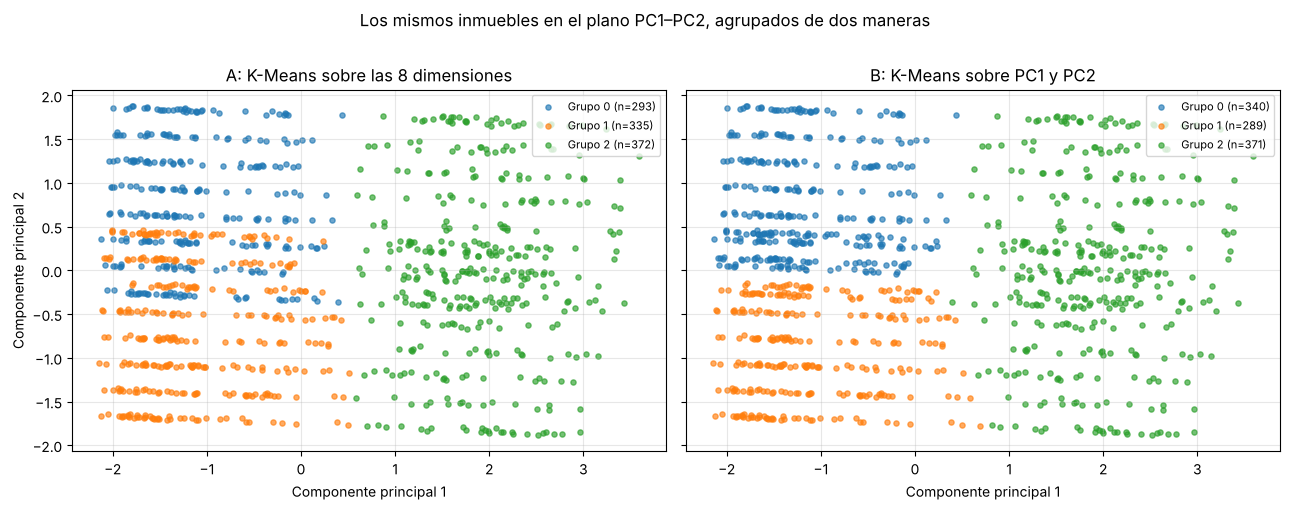

In [14]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for eje, etiquetas, titulo in zip(ejes, (grupos_A, grupos_B),
                                  ("A: K-Means sobre las 8 dimensiones", "B: K-Means sobre PC1 y PC2")):
    for g in range(3):
        m = etiquetas == g
        eje.scatter(X_pca[m, 0], X_pca[m, 1], s=14, alpha=0.65, color=COLORES[g], label=f"Grupo {g} (n={m.sum()})")
    eje.set(xlabel="Componente principal 1", title=titulo); eje.legend(fontsize=8)
ejes[0].set_ylabel("Componente principal 2")
plt.suptitle("Los mismos inmuebles en el plano PC1–PC2, agrupados de dos maneras", y=1.01)
plt.tight_layout(); plt.show()

### 6.1. ¿Qué variables separan realmente a los grupos?

Para saber qué impulsa cada agrupación se calcula, para cada variable, qué proporción de su varianza explica la
pertenencia al grupo (η², entre 0 y 1). Un valor alto significa que el grupo "se define" por esa variable.

In [15]:
tabla_eta = pd.DataFrame({
    "A: 8 dimensiones": [eta_cuadrado(v, grupos_A) for v in variables_numericas],
    "B: 2 componentes": [eta_cuadrado(v, grupos_B) for v in variables_numericas],
}, index=variables_numericas).round(3)
tabla_eta

,A: 8 dimensiones,B: 2 componentes
Precio_arriendo,0.738,0.736
Area_m2,0.714,0.715
Habitaciones,0.678,0.677
Banos,0.627,0.239
Antiguedad_anios,0.003,0.203


Esto confirma lo que muestran los perfiles. En ambos experimentos los grupos se definen por precio, área y
habitaciones (η² cercano a 0.7), pero en A el segundo factor es el **número de baños** (η² = 0.627) y casi nada la
antigüedad (0.003), mientras que en B el corte se reparte entre baños (0.239) y antigüedad (0.203), porque PC2
mezcla las dos. **Baños y antigüedad no tienen ninguna relación con el valor del inmueble, y aun así K-Means los usa
para separar grupos** porque sus varianzas (ya estandarizadas) pesan tanto como la del precio.

---
## 7. Variante informativa: PCA con las variables que describen al inmueble

El notebook 1 mostró que baños, antigüedad y localidad no se relacionan con las demás variables, mientras que
precio, área, habitaciones y estrato son redundantes entre sí. Eso es justo el escenario donde PCA luce: cuando
varias variables dicen lo mismo, un solo componente puede resumirlas. Lo compruebo repitiendo PCA con las cuatro
variables del notebook 1 (área, habitaciones, estrato y precio).

In [16]:
var_inf = ["Area_m2", "Habitaciones", "Estrato", "Precio_arriendo"]
X_inf = StandardScaler().fit_transform(df[var_inf])

pca_inf = PCA().fit(X_inf)
print("Varianza explicada por componente (4 variables informativas):")
print((pca_inf.explained_variance_ratio_ * 100).round(2))
print("Acumulada:", (pca_inf.explained_variance_ratio_.cumsum() * 100).round(2))
print()
print("Cargas:")
print(pd.DataFrame(pca_inf.components_.T, index=var_inf, columns=["PC1", "PC2", "PC3", "PC4"]).round(3).to_string())

Z_inf = PCA(n_components=2).fit_transform(X_inf)

Varianza explicada por componente (4 variables informativas):
[85.13  6.13  5.11  3.62]
Acumulada: [ 85.13  91.27  96.38 100.  ]

Cargas:
                   PC1    PC2    PC3    PC4
Area_m2          0.494 -0.686 -0.471 -0.253
Habitaciones     0.493  0.725 -0.383 -0.290
Estrato          0.512  0.020  0.047  0.857
Precio_arriendo  0.501 -0.059  0.793 -0.341


ARI frente a K-Means sobre las 4 variables escaladas:
  K-Means sobre PC1 solamente : 0.995   (silueta 0.743)
  K-Means sobre PC1 y PC2     : 0.995   (silueta 0.602)
  K-Means sobre las 4 variables: silueta 0.482

Inmuebles por grupo (4 variables): [419, 209, 372]
Inmuebles por grupo (solo PC1)   : [419, 207, 374]


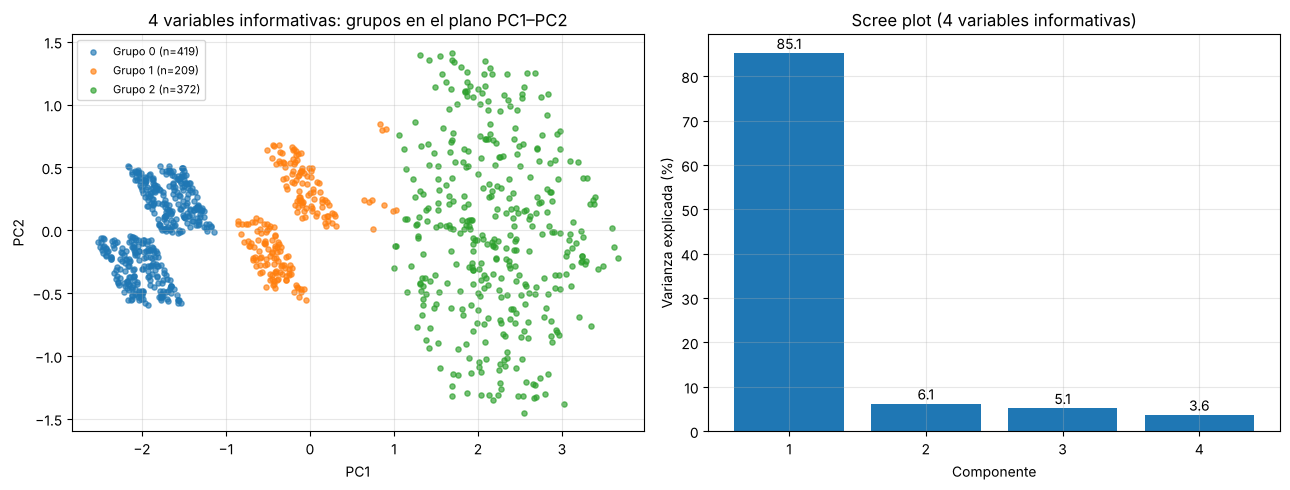

In [17]:
grupos_4v = ordenar_por_precio(KMeans(3, random_state=42, n_init=10).fit_predict(X_inf))          # como en el notebook 1
grupos_1pc = ordenar_por_precio(KMeans(3, random_state=42, n_init=10).fit_predict(Z_inf[:, :1]))   # solo PC1
grupos_2pc = ordenar_por_precio(KMeans(3, random_state=42, n_init=10).fit_predict(Z_inf))          # PC1 y PC2

print("ARI frente a K-Means sobre las 4 variables escaladas:")
print(f"  K-Means sobre PC1 solamente : {adjusted_rand_score(grupos_4v, grupos_1pc):.3f}   (silueta {silhouette_score(Z_inf[:, :1], grupos_1pc):.3f})")
print(f"  K-Means sobre PC1 y PC2     : {adjusted_rand_score(grupos_4v, grupos_2pc):.3f}   (silueta {silhouette_score(Z_inf, grupos_2pc):.3f})")
print(f"  K-Means sobre las 4 variables: silueta {silhouette_score(X_inf, grupos_4v):.3f}")
print()
print("Inmuebles por grupo (4 variables):", np.bincount(grupos_4v).tolist())
print("Inmuebles por grupo (solo PC1)   :", np.bincount(grupos_1pc).tolist())

fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
for g in range(3):
    m = grupos_4v == g
    ejes[0].scatter(Z_inf[m, 0], Z_inf[m, 1], s=14, alpha=0.65, color=COLORES[g], label=f"Grupo {g} (n={m.sum()})")
ejes[0].set(xlabel="PC1", ylabel="PC2", title="4 variables informativas: grupos en el plano PC1–PC2")
ejes[0].legend(fontsize=8)
x = np.arange(1, 5)
ejes[1].bar(x, pca_inf.explained_variance_ratio_ * 100, color="tab:blue")
for i, v in enumerate(pca_inf.explained_variance_ratio_ * 100):
    ejes[1].text(i + 1, v + 1, f"{v:.1f}", ha="center")
ejes[1].set(xlabel="Componente", ylabel="Varianza explicada (%)", title="Scree plot (4 variables informativas)")
ejes[1].set_xticks(x)
plt.tight_layout(); plt.show()

**Aquí PCA luce.** Con las cuatro variables de tamaño y valor, el **PC1 concentra el 85.1 %** de la varianza (y dos
componentes el 91.3 %). Las cuatro cargas en PC1 son casi iguales (0.49–0.51): PC1 es un índice general de tamaño y
valor. Cuatro variables redundantes se resumen en una sola.

Lo más importante: K-Means sobre **PC1 solamente** reproduce prácticamente los mismos tres segmentos que sobre
las cuatro variables (ARI = 0.995; 419 / 207 / 374 inmuebles frente a 419 / 209 / 372), y sobre PC1 y PC2 también
(ARI = 0.995). Es decir, pasar de 4 dimensiones a 1 casi no cambia los grupos. En el plano (panel izquierdo) los
tres segmentos son tres bandas verticales ordenadas por PC1, sin la partición artificial por baños de los
experimentos A y B.

---
## 8. Respuestas a las preguntas del enunciado (PCA)

**1. ¿Cuántas dimensiones tenía el conjunto de datos antes del preprocesamiento y cuántas tiene después de aplicar PCA?**
Antes del preprocesamiento, **6 características** de entrada (precio, área, habitaciones, baños, antigüedad y
localidad), es decir, una matriz de 1 000 × 6. Después del preprocesamiento, **8 columnas** (la localidad se
expande en 3 columnas one-hot). Después de PCA, **2 dimensiones** (1 000 × 2): los mismos 1 000 inmuebles, cada uno
representado con dos coordenadas.

**2. ¿Qué porcentaje de la varianza explican los dos primeros componentes?**
**62.9 %**: 45.1 % el PC1 y 17.8 % el PC2. Se pierde el 37.1 %. Para llegar al 80 % hacen falta 3 componentes, y para
el 90 %, 5.

**3. ¿Qué información puede perderse al representar los datos mediante dos componentes?**
Se pierde el 37.1 % de la varianza, de forma desigual: de precio, área y habitaciones se recupera cerca del
85 %; de baños y antigüedad, solo la mitad; y de la localidad, prácticamente nada. Además, las distancias en el plano
distorsionan las distancias reales (dos inmuebles cercanos en el plano pueden diferir en los componentes
descartados), los componentes son mezclas de variables y son más difíciles de interpretar, y PCA solo captura
relaciones lineales.

**4. ¿Los grupos identificados por K-Means se distinguen visualmente en el plano PC1–PC2?**
**Parcialmente.** El grupo premium se separa con claridad a lo largo de PC1 (derecha del plano), aunque con un borde
difuso. Los otros dos grupos se distinguen por una frontera horizontal en PC2, pero esa separación es artificial: son
inmuebles con el mismo precio y tamaño que solo difieren en baños. No hay vacíos entre grupos; los bordes son
transiciones continuas.

**5. ¿Qué diferencias comerciales existen entre los segmentos encontrados?**
Comercialmente solo hay **dos** segmentos: el **pequeño** (grupos 0 y 1: unos 2 millones de arriendo, 61 m²,
1.8 habitaciones; 628 inmuebles) y el **premium** (grupo 2: 6.35 millones, 156 m², 4 habitaciones; 372 inmuebles,
el 37.2 %). Los grupos 0 y 1 difieren únicamente en el número de baños (2 frente a 1), un atributo que no se
relaciona con el precio (3.60 frente a 3.67 millones en promedio). La localidad no distingue ninguno de los grupos.

**6. ¿Cambian los grupos al aplicar K-Means sobre los componentes principales en lugar de las variables preprocesadas?**
Depende de cuántos componentes se usen. Con **2 componentes sí cambian** (ARI = 0.711; 127 inmuebles, el 12.7 %,
cambian de grupo, casi todos del bloque pequeño; el premium casi no cambia). Con **3 componentes o más** (80 % de la
varianza) los grupos son **idénticos** (ARI = 1.000). Con las cuatro variables informativas, K-Means sobre PC1 reproduce
los grupos de las cuatro variables (ARI = 0.995).

**7. ¿Qué enfoque recomendaría para la inmobiliaria y por qué?**
Recomiendo **K-Means con k = 3 sobre las variables informativas** (área, habitaciones, estrato y precio,
estandarizadas), usando **PCA como herramienta de diagnóstico y visualización**, y describiendo los segmentos
*después* con baños, antigüedad y localidad en lugar de usarlas para construirlos. Razones:

- Produce los tres segmentos con significado comercial (económico, intermedio y premium, del notebook 1), mientras
  que usar las 8 columnas (A) o 2 componentes (B) genera una partición artificial por baños en el bloque pequeño.
- Baños, antigüedad y localidad no se relacionan con el valor del inmueble ni con las demás variables; al
  estandarizarlas pesan lo mismo que el precio y desvían a K-Means.
- Con las variables informativas PCA comprime 4 variables en 1 componente con el 85.1 % de la varianza, y el
  resultado es prácticamente el mismo (ARI = 0.995), lo que permite visualizar y explicar los segmentos en una sola
  escala de "tamaño y valor".
- Si en el futuro se demuestra que baños, antigüedad o ubicación influyen en el valor, se incluirían de nuevo.

---
## 9. Conclusiones

1. **PCA reveló la estructura del dataset.** La única estructura compartida entre variables es un factor, "tamaño y
   valor" (PC1, 45 % de la varianza), común a precio, área y habitaciones. Baños, antigüedad y localidad forman direcciones
   independientes que no se relacionan con el valor.
2. **El 62.9 % de la varianza con dos componentes** da una visualización razonable, pero oculta la localidad y la
   mitad de baños y antigüedad. Con tres componentes se llega al 80 %.
3. **Agrupar con todas las variables, o con dos componentes, genera segmentos engañosos**: se parte el bloque
   pequeño por baños (A) o por una mezcla de baños y antigüedad (B), sin diferencias comerciales.
4. **Usar PCA sobre variables redundantes sí funciona**: cuatro variables se resumen en un componente (85.1 %) con
   los mismos tres segmentos del notebook 1.
5. **Conclusión de método:** PCA y K-Means no son procedimientos que se aplican de forma automática. Hay que
   decidir qué variables entran, comprobar qué significa cada componente (las cargas) y qué variables definen los
   grupos (η²), porque un resultado con buena apariencia (una gráfica con tres colores) puede no tener sentido
   comercial.